# 05 — Série temporal e projeção
**Arquivo:** 05-serie-temporal.ipynb
**Objetivo:** comparar métodos simples de projeção da vacância ponderada e projetar os próximos trimestres
**Entrada:** dados/gold/vacancia_segmento_trimestral.parquet
**Saída:** monografia/figuras/fig05_*.png; dados/gold/projecao_vacancia_trimestral.parquet
**Onde roda:** local (.venv, pandas, numpy, matplotlib) — **Camada:** Gold → análise

In [1]:
# Bibliotecas: pandas lê a Gold; numpy faz as contas dos métodos (média,
# reta, erro); matplotlib e seaborn desenham a figura da projeção.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Caminhos centralizados, mesmo padrão dos notebooks anteriores.
RAIZ = Path("..").resolve()
GOLD = RAIZ / "dados" / "gold"
FIGURAS = RAIZ / "monografia" / "figuras"

# Lê a Gold do segmento e garante a ordem cronológica. Em série temporal, a
# ordem das linhas é o próprio tempo; não se pode depender de o arquivo já vir
# ordenado.
df = pd.read_parquet(GOLD / "vacancia_segmento_trimestral.parquet")
df = df.sort_values(['ano', 'Trimestre']).reset_index(drop=True)

# Monta a série: período, vacância (escala 0 a 1, como na Gold) e um contador
# de tempo t = 0, 1, 2... usado pela reta da tendência linear, que precisa do
# tempo como número.
serie = df[['periodo', 'vacancia_ponderada']].copy()
serie['t'] = range(len(serie))

print("Trimestres na série:", len(serie), "| Esperado 26?", len(serie) == 26)
print("Primeiro:", serie['periodo'].iloc[0], "| Último:", serie['periodo'].iloc[-1])

sns.set_theme(style="whitegrid")

Trimestres na série: 26 | Esperado 26? True
Primeiro: 2020-T1 | Último: 2026-T2


In [2]:
# Separação temporal: os 22 primeiros trimestres treinam os métodos e os 4
# últimos ficam escondidos como prova. Os últimos, e não sorteados, porque a
# projeção real só conhece o passado.
N_TESTE = 4
treino = serie.iloc[:-N_TESTE]
teste = serie.iloc[-N_TESTE:]
y_treino = treino['vacancia_ponderada']
y_teste = teste['vacancia_ponderada'].values

# Método 1 — ingênuo: repete o último valor do treino nos 4 trimestres.
# Serve de linha de base: outro método só vale se errar menos que ele.
prev_ingenuo = np.repeat(y_treino.iloc[-1], N_TESTE)

# Método 2 — média móvel de 4 trimestres: repete a média do último ano do
# treino, suavizando oscilações de um trimestre isolado.
prev_media = np.repeat(y_treino.iloc[-4:].mean(), N_TESTE)

# Método 3 — tendência linear: ajusta a reta que melhor passa pelos pontos
# do treino (vacância × t) e a prolonga até os trimestres do teste.
inclinacao, intercepto = np.polyfit(treino['t'], y_treino, 1)
prev_linear = inclinacao * teste['t'].values + intercepto

# Tabela de comparação trimestre a trimestre, em % só para leitura.
comparacao = pd.DataFrame({
    'periodo': teste['periodo'].values,
    'real': y_teste * 100,
    'ingenuo': prev_ingenuo * 100,
    'media_movel_4': prev_media * 100,
    'tendencia_linear': prev_linear * 100,
})
print(comparacao.round(2))

# MAE de cada método: média das diferenças absolutas entre real e previsto,
# em pontos percentuais. O menor MAE indica o método que errou menos no teste.
mae = pd.Series({
    'Ingênuo': np.abs(y_teste - prev_ingenuo).mean() * 100,
    'Média móvel (4 trimestres)': np.abs(y_teste - prev_media).mean() * 100,
    'Tendência linear': np.abs(y_teste - prev_linear).mean() * 100,
}).sort_values()
print("\nMAE (pontos percentuais), do menor para o maior:")
print(mae.round(2))
print("\nInclinação da reta (pontos por trimestre):", round(inclinacao * 100, 3))

   periodo  real  ingenuo  media_movel_4  tendencia_linear
0  2025-T3  1.81     1.73           2.01              2.06
1  2025-T4  5.52     1.73           2.01              1.94
2  2026-T1  7.00     1.73           2.01              1.82
3  2026-T2  7.59     1.73           2.01              1.70

MAE (pontos percentuais), do menor para o maior:
Média móvel (4 trimestres)    3.57
Tendência linear              3.73
Ingênuo                       3.75
dtype: float64

Inclinação da reta (pontos por trimestre): -0.121


In [3]:
# Projeção final com o método escolhido (média móvel de 4 trimestres), agora
# usando a série inteira: a média dos 4 últimos valores observados é repetida
# nos 4 trimestres seguintes.
JANELA = 4
HORIZONTE = 4
valor_proj = serie['vacancia_ponderada'].iloc[-JANELA:].mean()

# Faixa de erro: projeção ± MAE do teste. O MAE estava em pontos percentuais
# e volta para a escala 0 a 1 (÷100) para ficar igual à Gold. O limite
# inferior nunca fica abaixo de zero, porque vacância negativa não existe.
mae_metodo = mae['Média móvel (4 trimestres)'] / 100

# Gera os rótulos dos próximos trimestres como um calendário: soma 1 ao
# trimestre; se passar de 4, volta para 1 e avança o ano.
ano = int(df['ano'].iloc[-1])
tri = int(df['Trimestre'].iloc[-1])
linhas = []
for i in range(HORIZONTE):
    tri = tri + 1
    if tri > 4:
        tri = 1
        ano = ano + 1
    linhas.append({'ano': ano, 'Trimestre': tri, 'periodo': f"{ano}-T{tri}"})

# Monta a tabela da projeção, continuando o contador de tempo t da série
# (26, 27, 28, 29), para desenhar tudo no mesmo eixo.
projecao = pd.DataFrame(linhas)
projecao['t'] = range(len(serie), len(serie) + HORIZONTE)
projecao['vacancia_projetada'] = valor_proj
projecao['limite_inferior'] = max(valor_proj - mae_metodo, 0)
projecao['limite_superior'] = valor_proj + mae_metodo
projecao['metodo'] = 'Média móvel de 4 trimestres'

# Grava na Gold (escala 0 a 1), para consumo no dashboard; t é só auxiliar
# do gráfico e fica fora do arquivo.
projecao.drop(columns='t').to_parquet(GOLD / "projecao_vacancia_trimestral.parquet", index=False)
print((projecao[['periodo', 'vacancia_projetada', 'limite_inferior', 'limite_superior']]
       .set_index('periodo') * 100).round(2))

         vacancia_projetada  limite_inferior  limite_superior
periodo                                                      
2026-T3                5.48             1.91             9.05
2026-T4                5.48             1.91             9.05
2027-T1                5.48             1.91             9.05
2027-T2                5.48             1.91             9.05


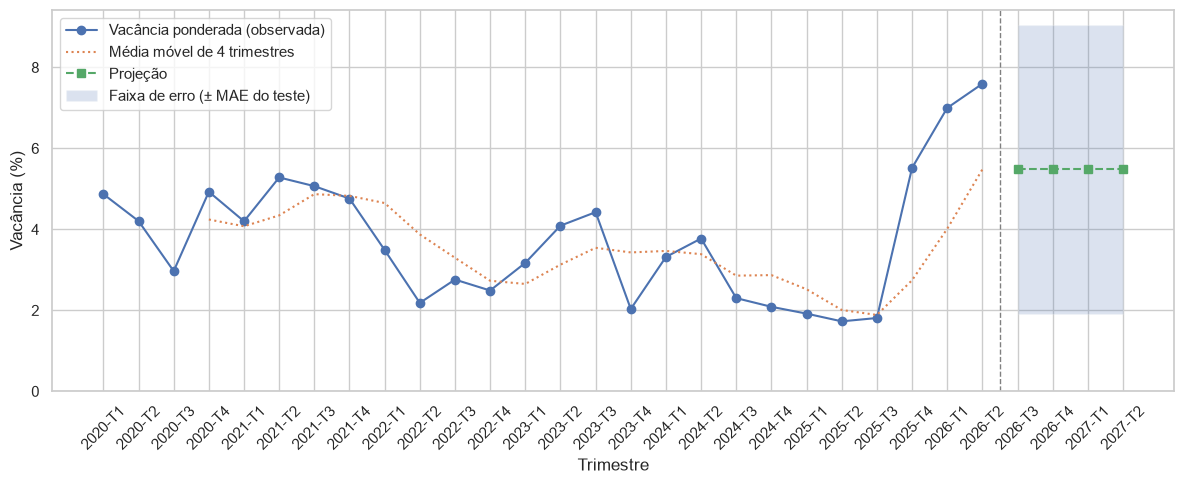

In [4]:
# Média móvel ao longo de toda a série, só para mostrar na figura como o
# método suaviza os dados (os 3 primeiros trimestres ficam vazios: ainda não
# há 4 valores para fazer a média).
serie['media_movel_4'] = serie['vacancia_ponderada'].rolling(JANELA).mean()

# Série observada, média móvel, projeção e faixa de erro no mesmo eixo, em %.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie['t'], serie['vacancia_ponderada'] * 100, marker='o',
        label='Vacância ponderada (observada)')
ax.plot(serie['t'], serie['media_movel_4'] * 100, linestyle=':',
        label='Média móvel de 4 trimestres')
ax.plot(projecao['t'], projecao['vacancia_projetada'] * 100, marker='s',
        linestyle='--', label='Projeção')
ax.fill_between(projecao['t'], projecao['limite_inferior'] * 100,
                projecao['limite_superior'] * 100, alpha=0.2,
                label='Faixa de erro (± MAE do teste)')

# Linha vertical separando observado de projetado.
ax.axvline(len(serie) - 0.5, color='grey', linestyle='--', linewidth=1)

# O eixo X usa o contador t (número); os rótulos de texto dos períodos são
# aplicados por cima, juntando os observados e os projetados.
rotulos = list(serie['periodo']) + list(projecao['periodo'])
ax.set_xticks(range(len(rotulos)))
ax.set_xticklabels(rotulos, rotation=45)
ax.set_xlabel('Trimestre')
ax.set_ylabel('Vacância (%)')
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')

# Salva antes de exibir, no padrão da DA-28.
fig.tight_layout()
fig.savefig(FIGURAS / "fig05_projecao_vacancia.png", dpi=300, bbox_inches='tight')
plt.show()

## Conclusões do notebook 05

**Comparação de métodos** (holdout temporal: treino de 2020-T1 a 2025-T2, teste de 2025-T3 a 2026-T2)

| Método | MAE (pontos percentuais) |
|---|---|
| Média móvel de 4 trimestres | 3,57 |
| Tendência linear | 3,73 |
| Ingênuo | 3,75 |

- No 2025-T3, os três métodos erram menos de 0,3 ponto. De 2025-T4 em diante, todos projetam até cerca de 2%, contra valores reais de 5,52% a 7,59%.
- A diferença entre os métodos é pequena (0,18 ponto). O erro é dominado pela ruptura de composição identificada no notebook 04.
- A tendência linear aprendida no treino era de queda (−0,121 ponto por trimestre), contrariada pelos dados seguintes.

**Projeção** (DA-13)

- 5,48% de 2026-T3 a 2027-T2, com faixa de erro de 1,91% a 9,05% (± MAE).
- A projeção é indicativa: a série tem 26 pontos e uma mudança de patamar recente.
- Arquivos: `gold/projecao_vacancia_trimestral.parquet` e `fig05_projecao_vacancia.png`.

**Limitações**

- O teste tem só 4 pontos, três deles posteriores à ruptura.
- A média móvel reage com atraso a mudanças de patamar.
- A faixa de erro não é um intervalo de confiança estatístico.